# 08 — Liên hệ Hình học Embedding với Popularity Bias & Accuracy trên Yoochoose + Đối chiếu chéo Diginetica

Đây là notebook tổng hợp cuối cùng nối kết **File 06** (Popularity Bias & Accuracy đầu ra) với **File 07** (Hình học không gian Embedding) trên **Yoochoose `1/32`**, đồng thời thực hiện **đối chiếu chéo trực tiếp với Diginetica** để trả lời mục tiêu nghiên cứu lớn nhất:

> **Câu hỏi cầu nối:** *Những khác biệt hình học trong không gian embedding (`L2 norm`, `khoảng cách tới tâm category`, `cosine với tâm category`) có đi kèm với việc item nhận nhiều exposure hơn và dễ dự đoán đúng (`hit@20`) hơn **sau khi giữ cố định `train_freq`** không? Và các quy luật tìm thấy trên Diginetica có lặp lại trên Yoochoose không?*

### Ba tầng phân tích chặt chẽ (không suy diễn nhân quả quá mức)
- **Tầng 1 (Mô tả theo nhóm)**: Đặt `norm`, `centroid distance`, `centroid cosine`, `exposure share` và `micro Recall@20` cạnh nhau trên `Popular / Medium / Rare`.
- **Tầng 2 (Tương quan thô & trong từng Frequency Bin)**: Tính 3 tương quan cốt lõi (`train_freq ↔ norm`, `train_freq ↔ rec_count`, `norm ↔ rec_count`) kèm kiểm tra trong từng bin tần suất để phát hiện biến gây nhiễu `train_freq`.
- **Tầng 3 (Kiểm soát `log(1 + train_freq)`)**:
  - **OLS chuẩn hóa** cho `log(1 + rec_count)` ở cấp item (`8.326` warm items) + kiểm tra độ nhạy trên riêng `12` category ngữ nghĩa chuẩn (`has_regular_category == True`).
  - **Logistic Regression** ở cấp truy vấn (`41.585` warm test queries/lần chạy) cho xác suất `hit@20`.
- **Tổng hợp liên-dataset**: So sánh trực tiếp toàn diện **Diginetica vs. Yoochoose `1/32`** trên cả 3 mô hình × 2 seed.

## 1. Thiết lập môi trường, nạp dữ liệu 6 lần chạy & ghép bảng Accuracy cấp truy vấn / cấp item

In [1]:
from __future__ import annotations

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "BTL-K03-tong-quan-de-tai.md").is_file():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án DA-3.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from btl_k03.paths import get_dataset_paths, ensure_output_dirs
from btl_k03.utils import load_yaml
from btl_k03.embedding_analysis import (
    analyze_three_core_relationships,
    attach_item_accuracy,
    build_query_and_item_accuracy_tables,
    compute_geometry_output_correlations,
    fit_geometry_accuracy_models,
    fit_geometry_exposure_models,
    summarize_geometry_and_outcomes_by_group,
)

DATASET = "yoochoose"
MODELS = ["gru4rec", "narm", "sasrec"]
MODEL_LABELS = {"gru4rec": "GRU4Rec", "narm": "NARM", "sasrec": "SASRec"}
MODEL_COLORS = {"GRU4REC": "#3182ce", "NARM": "#dd6b20", "SASREC": "#2f855a"}
GROUP_COLORS = {"popular": "#e53e3e", "medium": "#3182ce", "rare": "#38a169"}
SEEDS = [2024, 2025]
TOPK = 20

ensure_output_dirs(DATASET)
YOO_PATHS = get_dataset_paths(DATASET)
DIGI_PATHS = get_dataset_paths("diginetica")
COMMON_CFG = load_yaml(YOO_PATHS["config_dir"] / "common.yaml")
FINAL_BOOT = int(COMMON_CFG["embedding_geometry"].get("final_analysis_bootstrap_iterations", 500))

PROCESSED_DIR = YOO_PATHS["processed_dir"]
RUNS_DIR = YOO_PATHS["runs_dir"]
ITEM_LEVEL_DIR = YOO_PATHS["item_level_dir"]
TABLES_DIR = YOO_PATHS["tables_dir"]
FIGURES_DIR = YOO_PATHS["figures_dir"]
STAT_TESTS_DIR = YOO_PATHS["stat_tests_dir"]

test_examples = pd.read_parquet(PROCESSED_DIR / "test_examples.parquet")
model_acc_df = pd.read_csv(TABLES_DIR / "model_accuracy.csv")
pop_bias_df = pd.read_csv(TABLES_DIR / "popularity_bias.csv")
cosine_gap_df = pd.read_csv(TABLES_DIR / "cosine_gap_seed_summary.csv")
aniso_pca_df = pd.read_csv(TABLES_DIR / "embedding_anisotropy_pca.csv")

enriched_tables: dict[tuple[str, int], pd.DataFrame] = {}
query_tables: dict[tuple[str, int], pd.DataFrame] = {}

load_check = []
for m in MODELS:
    for seed in SEEDS:
        il = pd.read_parquet(ITEM_LEVEL_DIR / f"{m}_seed{seed}.parquet")
        t20 = pd.read_parquet(RUNS_DIR / m / f"seed_{seed}" / "top20.parquet")
        q_df, item_acc = build_query_and_item_accuracy_tables(test_examples, t20, topk=TOPK)
        enriched = attach_item_accuracy(il, item_acc, topk=TOPK)

        # Kiểm chứng micro Recall@20 khớp tuyệt đối với model_accuracy.csv
        recalc_recall = float(q_df[f"hit@{TOPK}"].mean())
        logged_recall = float(
            model_acc_df.loc[(model_acc_df["model"] == m.upper()) & (model_acc_df["seed"] == seed), "recall@20"].iloc[0]
        )
        assert np.isclose(recalc_recall, logged_recall, atol=1e-9)

        enriched_tables[(m, seed)] = enriched
        query_tables[(m, seed)] = q_df
        load_check.append(
            {
                "model": m.upper(),
                "seed": seed,
                "warm_items": int(enriched["is_trainable_warm"].sum()),
                "warm_items_with_test_target": int((enriched["is_trainable_warm"] & (enriched["target_count"] > 0)).sum()),
                "test_queries": len(q_df),
                "verified_recall@20": recalc_recall,
            }
        )

display(pd.DataFrame(load_check))
print("Đã ghép & kiểm chứng khớp 100% bảng cấp truy vấn và cấp item cho cả 6 lần chạy.")

,model,seed,warm_items,warm_items_with_test_target,test_queries,verified_recall@20
0,GRU4REC,2024,8326,3943,41585,0.7312
1,GRU4REC,2025,8326,3943,41585,0.7287
2,NARM,2024,8326,3943,41585,0.7350
3,NARM,2025,8326,3943,41585,0.7347
4,SASREC,2024,8326,3943,41585,0.7394
5,SASREC,2025,8326,3943,41585,0.7415


Đã ghép & kiểm chứng khớp 100% bảng cấp truy vấn và cấp item cho cả 6 lần chạy.


## 2. Tầng 1 — Đặt Hình học Embedding, Exposure và Accuracy cạnh nhau theo nhóm Popularity

Quan sát xem khi đi từ `Rare → Medium → Popular`, bốn đại lượng (`norm`, `centroid distance`, `exposure share`, `micro Recall@20`) biến thiên đồng thời như thế nào trên Yoochoose.

=== BẢNG 1A: HÌNH HỌC, EXPOSURE VÀ RECALL@20 THEO NHÓM POPULARITY (TB 2 SEED) ===


,model,popularity_group,item_count,train_frequency_mean,embedding_norm_mean,centroid_distance_mean,centroid_cosine_mean,exposure_share_pct,within_group_coverage_pct,recall@20
0,GRU4REC,popular,"1,684.0000",284.0404,1.1128,1.0689,0.3140,89.1824,99.8515,0.7553
1,GRU4REC,medium,"4,695.0000",17.2952,1.3354,1.1706,0.4734,9.7278,94.1960,0.5504
2,GRU4REC,rare,"1,947.0000",5.8706,1.4726,1.2529,0.5304,1.0898,76.5280,0.4052
3,NARM,popular,"1,684.0000",284.0404,1.0781,1.0122,0.3458,88.8163,99.8812,0.7588
4,NARM,medium,"4,695.0000",17.2952,1.1928,1.0754,0.4248,10.0230,95.3781,0.5666
5,NARM,rare,"1,947.0000",5.8706,1.2591,1.1150,0.4662,1.1607,79.4042,0.4191
6,SASREC,popular,"1,684.0000",284.0404,0.8935,0.8697,0.2815,87.9363,99.8219,0.7618
7,SASREC,medium,"4,695.0000",17.2952,1.0741,0.9415,0.4772,10.7064,94.9521,0.5904
8,SASREC,rare,"1,947.0000",5.8706,1.1707,0.9859,0.5486,1.3573,81.9466,0.4591



=== BẢNG 1B: CHÊNH LỆCH POPULAR ↔ RARE (TB ± STD QUA 2 SEED) ===


,model,norm_gap_rare_minus_popular_mean,norm_gap_rare_minus_popular_std,centroid_dist_gap_rare_minus_popular_mean,centroid_dist_gap_rare_minus_popular_std,centroid_cos_gap_popular_minus_rare_mean,centroid_cos_gap_popular_minus_rare_std,exposure_gap_popular_minus_rare_pp_mean,exposure_gap_popular_minus_rare_pp_std,recall_gap_popular_minus_rare_pp_mean,recall_gap_popular_minus_rare_pp_std
0,GRU4REC,0.3598,0.0296,0.1841,0.0244,-0.2164,0.0026,88.0926,0.2560,35.0084,0.0747
1,NARM,0.1810,0.0517,0.1028,0.0537,-0.1205,0.0188,87.6556,0.1468,33.9647,0.4212
2,SASREC,0.2772,0.0500,0.1162,0.0426,-0.2670,0.0144,86.5791,0.2093,30.2685,1.2608


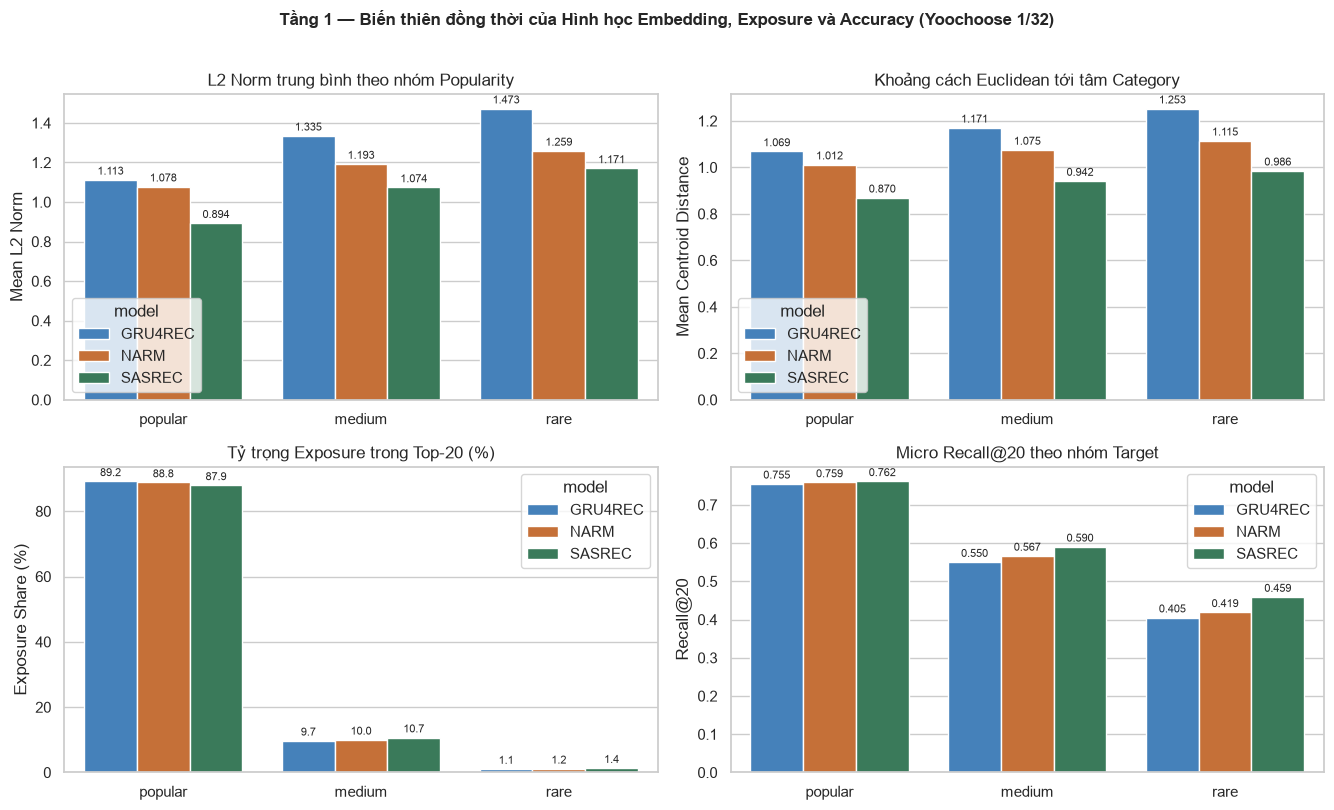

In [2]:
group_frames = []
gap_rows = []

for m in MODELS:
    for seed in SEEDS:
        g_df = summarize_geometry_and_outcomes_by_group(enriched_tables[(m, seed)], topk=TOPK)
        g_df["model"] = m.upper()
        group_frames.append(g_df)

        g_idx = g_df.set_index("popularity_group")
        gap_rows.append(
            {
                "model": m.upper(),
                "seed": seed,
                "norm_gap_rare_minus_popular": float(g_idx.loc["rare", "embedding_norm_mean"] - g_idx.loc["popular", "embedding_norm_mean"]),
                "centroid_dist_gap_rare_minus_popular": float(g_idx.loc["rare", "centroid_distance_mean"] - g_idx.loc["popular", "centroid_distance_mean"]),
                "centroid_cos_gap_popular_minus_rare": float(g_idx.loc["popular", "centroid_cosine_mean"] - g_idx.loc["rare", "centroid_cosine_mean"]),
                "exposure_gap_popular_minus_rare_pp": float(g_idx.loc["popular", "exposure_share_pct"] - g_idx.loc["rare", "exposure_share_pct"]),
                "recall_gap_popular_minus_rare_pp": float((g_idx.loc["popular", f"recall@{TOPK}"] - g_idx.loc["rare", f"recall@{TOPK}"]) * 100.0),
            }
        )

group_summary_df = pd.concat(group_frames, ignore_index=True)
group_summary_df.to_csv(TABLES_DIR / "geometry_bias_group_summary.csv", index=False)

group_seed_summary = (
    group_summary_df.groupby(["model", "popularity_group"], sort=False)[
        ["item_count", "train_frequency_mean", "embedding_norm_mean", "centroid_distance_mean", "centroid_cosine_mean", "exposure_share_pct", "within_group_coverage_pct", f"recall@{TOPK}"]
    ]
    .mean()
    .reset_index()
)
group_seed_summary.to_csv(TABLES_DIR / "geometry_bias_group_seed_summary.csv", index=False)

gap_summary_df = pd.DataFrame(gap_rows)
gap_summary_df.to_csv(TABLES_DIR / "geometry_bias_gap_summary.csv", index=False)

gap_seed_summary = (
    gap_summary_df.groupby("model", sort=False)[
        ["norm_gap_rare_minus_popular", "centroid_dist_gap_rare_minus_popular", "centroid_cos_gap_popular_minus_rare", "exposure_gap_popular_minus_rare_pp", "recall_gap_popular_minus_rare_pp"]
    ]
    .agg(["mean", "std"])
)
gap_seed_summary.columns = [f"{a}_{b}" for a, b in gap_seed_summary.columns]
gap_seed_summary = gap_seed_summary.reset_index()
gap_seed_summary.to_csv(TABLES_DIR / "geometry_bias_gap_seed_summary.csv", index=False)

print("=== BẢNG 1A: HÌNH HỌC, EXPOSURE VÀ RECALL@20 THEO NHÓM POPULARITY (TB 2 SEED) ===")
display(group_seed_summary)

print("\n=== BẢNG 1B: CHÊNH LỆCH POPULAR ↔ RARE (TB ± STD QUA 2 SEED) ===")
display(gap_seed_summary)

fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.0))
m_order = ["GRU4REC", "NARM", "SASREC"]
g_order = ["popular", "medium", "rare"]

for ax, col, title, ylabel, fmt in [
    (axes[0, 0], "embedding_norm_mean", "L2 Norm trung bình theo nhóm Popularity", "Mean L2 Norm", "%.3f"),
    (axes[0, 1], "centroid_distance_mean", "Khoảng cách Euclidean tới tâm Category", "Mean Centroid Distance", "%.3f"),
    (axes[1, 0], "exposure_share_pct", "Tỷ trọng Exposure trong Top-20 (%)", "Exposure Share (%)", "%.1f"),
    (axes[1, 1], f"recall@{TOPK}", "Micro Recall@20 theo nhóm Target", "Recall@20", "%.3f"),
]:
    sns.barplot(
        data=group_seed_summary, x="popularity_group", y=col, hue="model",
        order=g_order, hue_order=m_order, palette=MODEL_COLORS, ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, fontsize=8, padding=2)

plt.suptitle("Tầng 1 — Biến thiên đồng thời của Hình học Embedding, Exposure và Accuracy (Yoochoose 1/32)", fontsize=12.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "geometry_bias_group_link.png", dpi=160, bbox_inches="tight")
plt.show()

## 3. Tầng 2 — Ba tương quan cốt lõi, tương quan trong từng Frequency Bin & Cảnh báo biến gây nhiễu `train_freq`

Phân tích 3 mối quan hệ trên tập warm (`8.326` items):
1. `train_freq ↔ embedding_norm`
2. `train_freq ↔ rec_count`
3. `embedding_norm ↔ rec_count`

Đồng thời tính lại `norm ↔ rec_count` **bên trong từng nhóm (`rare`, `medium`, `popular`)** và tính toàn bộ tương quan giữa 3 biến hình học với cả `rec_count` lẫn `item_recall@20`.

In [3]:
core_frames = []
bin_frames = []
ols_norm_rows = []
geom_corr_frames = []

for m in MODELS:
    for seed in SEEDS:
        enr = enriched_tables[(m, seed)]
        c_df, b_df, reg_dict = analyze_three_core_relationships(
            enr, n_bootstrap=FINAL_BOOT, seed=seed
        )
        c_df["model"] = m.upper()
        b_df["model"] = m.upper()
        reg_dict["model"] = m.upper()
        core_frames.append(c_df)
        bin_frames.append(b_df)
        ols_norm_rows.append(reg_dict)

        gc_df = compute_geometry_output_correlations(enr, topk=TOPK)
        gc_df["model"] = m.upper()
        geom_corr_frames.append(gc_df)

core_rel_df = pd.concat(core_frames, ignore_index=True)
within_bin_df = pd.concat(bin_frames, ignore_index=True)
ols_norm_df = pd.DataFrame(ols_norm_rows)
geom_corr_df = pd.concat(geom_corr_frames, ignore_index=True)

core_rel_df.to_csv(TABLES_DIR / "bias_geometry_relationship.csv", index=False)
within_bin_df.to_csv(TABLES_DIR / "within_bin_norm_rec.csv", index=False)
ols_norm_df.to_csv(STAT_TESTS_DIR / "norm_rec_ols_summary.csv", index=False)
geom_corr_df.to_csv(STAT_TESTS_DIR / "geometry_output_correlations.csv", index=False)

core_pivot = (
    core_rel_df.loc[core_rel_df["scope"] == "warm_only"]
    .groupby(["model", "pair"], sort=False)["rho"]
    .mean()
    .unstack("pair")
    .reset_index()
)
print("=== BẢNG 2A: BA TƯƠNG QUAN SPEARMAN CỐT LÕI (WARM ONLY — TB 2 SEED) ===")
display(core_pivot)

bin_pivot = (
    within_bin_df.groupby(["model", "popularity_group"], sort=False)["norm_rec_rho"]
    .mean()
    .unstack("popularity_group")[["rare", "medium", "popular"]]
    .reset_index()
)
print("\n=== BẢNG 2B: SPEARMAN(NORM, REC_COUNT) BÊN TRONG TỪNG FREQUENCY BIN (GIẢM NHIỄU TẦN SUẤT) ===")
display(bin_pivot)

print("\n=== BẢNG 2C: TƯƠNG QUAN THÔ GEOMETRY ↔ OUTCOME TRÊN TOÀN WARM CATALOG (TB 2 SEED) ===")
display(
    geom_corr_df.loc[geom_corr_df["scope"] == "all_warm"]
    .groupby(["model", "geometry_variable", "outcome"], sort=False)["rho"]
    .mean()
    .unstack("outcome")
    .reset_index()
)

=== BẢNG 2A: BA TƯƠNG QUAN SPEARMAN CỐT LÕI (WARM ONLY — TB 2 SEED) ===


pair,model,train_freq <-> embedding_norm,train_freq <-> rec_count,embedding_norm <-> rec_count
0,GRU4REC,-0.6803,0.7572,-0.5838
1,NARM,-0.5504,0.7526,-0.4583
2,SASREC,-0.6364,0.7213,-0.5244



=== BẢNG 2B: SPEARMAN(NORM, REC_COUNT) BÊN TRONG TỪNG FREQUENCY BIN (GIẢM NHIỄU TẦN SUẤT) ===


popularity_group,model,rare,medium,popular
0,GRU4REC,-0.0653,-0.3137,-0.5410
1,NARM,0.0024,-0.2187,-0.3915
2,SASREC,-0.0287,-0.2566,-0.5221



=== BẢNG 2C: TƯƠNG QUAN THÔ GEOMETRY ↔ OUTCOME TRÊN TOÀN WARM CATALOG (TB 2 SEED) ===


outcome,model,geometry_variable,rec_count,item_recall@20
0,GRU4REC,embedding_norm,-0.5838,-0.0060
1,GRU4REC,distance_to_category_centroid,-0.4014,0.0071
2,GRU4REC,cosine_to_category_centroid,-0.3804,-0.0296
3,NARM,embedding_norm,-0.4583,0.0636
4,NARM,distance_to_category_centroid,-0.2643,0.0588
5,NARM,cosine_to_category_centroid,-0.2088,-0.0304
6,SASREC,embedding_norm,-0.5244,0.0763
7,SASREC,distance_to_category_centroid,-0.3031,0.1130
8,SASREC,cosine_to_category_centroid,-0.4880,-0.0343


## 4. Biểu đồ liên hệ `train_freq ↔ rec_count` và `embedding_norm ↔ rec_count` (cả 2 seed)

Trực quan hóa trực tiếp quan hệ giữa tần suất train, L2 norm và số lần item xuất hiện trong Top-20 (`log10(1 + rec_count)`) theo từng nhóm `Popular / Medium / Rare` để đối chiếu độ phân tầng hình học–exposure trên Yoochoose.

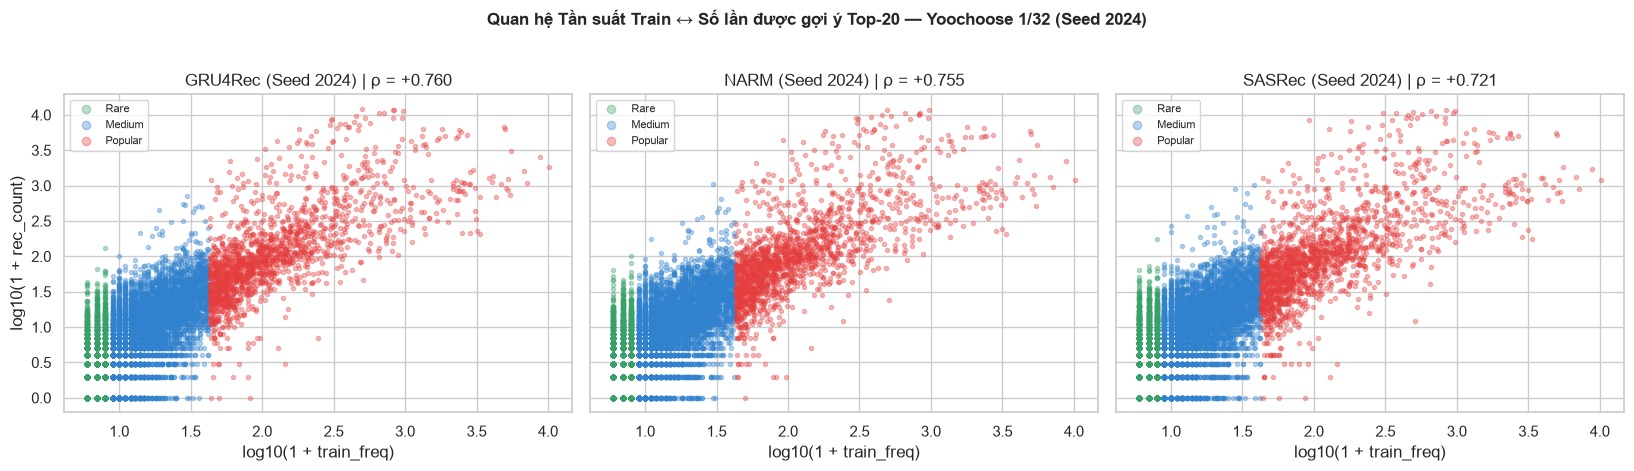

D:\Temp\ipykernel_8464\3002624256.py:50: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
D:\Temp\ipykernel_8464\3002624256.py:51: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(FIGURES_DIR / f"norm_recommendation_relationship_seed{seed}.png", dpi=160, bbox_inches="tight")
D:\Temp\ipykernel_8464\3002624256.py:53: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(FIGURES_DIR / "norm_recommendation_relationship.png", dpi=160, bbox_inches="tight")
d:\DL\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


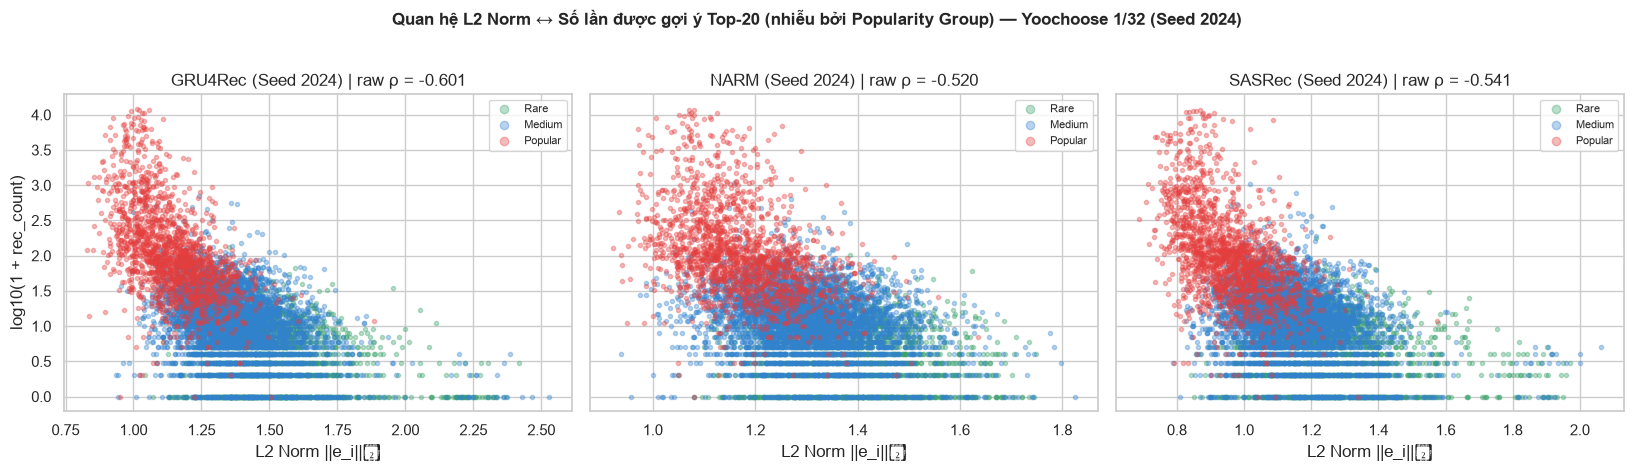

In [4]:
for seed in SEEDS:
    # 1. Scatter log10(1 + train_freq) vs log10(1 + rec_count)
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6), sharey=True)
    for ax, m in zip(axes, MODELS):
        warm = enriched_tables[(m, seed)].loc[lambda d: d["is_trainable_warm"]]
        for grp in ["rare", "medium", "popular"]:
            sub = warm.loc[warm["popularity_group"] == grp]
            ax.scatter(
                np.log10(sub["train_freq"] + 1.0), np.log10(sub["rec_count"] + 1.0),
                s=9, alpha=0.35, color=GROUP_COLORS[grp], label=grp.capitalize(), rasterized=True,
            )
        rho_fr = core_rel_df.loc[
            (core_rel_df["model"] == m.upper()) & (core_rel_df["seed"] == seed)
            & (core_rel_df["scope"] == "warm_only") & (core_rel_df["pair"] == "train_freq <-> rec_count"),
            "rho",
        ].iloc[0]
        ax.set_title(f"{MODEL_LABELS[m]} (Seed {seed}) | ρ = {rho_fr:+.3f}")
        ax.set_xlabel("log10(1 + train_freq)")
        ax.set_ylabel("log10(1 + rec_count)" if ax is axes[0] else "")
        ax.legend(loc="upper left", fontsize=8, markerscale=2)
    plt.suptitle(f"Quan hệ Tần suất Train ↔ Số lần được gợi ý Top-20 — Yoochoose 1/32 (Seed {seed})", fontsize=12.5, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"frequency_recommendation_relationship_seed{seed}.png", dpi=160, bbox_inches="tight")
    if seed == SEEDS[0]:
        plt.savefig(FIGURES_DIR / "frequency_recommendation_relationship.png", dpi=160, bbox_inches="tight")
        plt.show()
    else:
        plt.close(fig)

    # 2. Scatter embedding_norm vs log10(1 + rec_count)
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6), sharey=True)
    for ax, m in zip(axes, MODELS):
        warm = enriched_tables[(m, seed)].loc[lambda d: d["is_trainable_warm"]]
        for grp in ["rare", "medium", "popular"]:
            sub = warm.loc[warm["popularity_group"] == grp]
            ax.scatter(
                sub["embedding_norm"], np.log10(sub["rec_count"] + 1.0),
                s=9, alpha=0.35, color=GROUP_COLORS[grp], label=grp.capitalize(), rasterized=True,
            )
        rho_nr = core_rel_df.loc[
            (core_rel_df["model"] == m.upper()) & (core_rel_df["seed"] == seed)
            & (core_rel_df["scope"] == "warm_only") & (core_rel_df["pair"] == "embedding_norm <-> rec_count"),
            "rho",
        ].iloc[0]
        ax.set_title(f"{MODEL_LABELS[m]} (Seed {seed}) | raw ρ = {rho_nr:+.3f}")
        ax.set_xlabel("L2 Norm ||e_i||₂")
        ax.set_ylabel("log10(1 + rec_count)" if ax is axes[0] else "")
        ax.legend(loc="upper right", fontsize=8, markerscale=2)
    plt.suptitle(f"Quan hệ L2 Norm ↔ Số lần được gợi ý Top-20 (nhiễu bởi Popularity Group) — Yoochoose 1/32 (Seed {seed})", fontsize=12.5, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"norm_recommendation_relationship_seed{seed}.png", dpi=160, bbox_inches="tight")
    if seed == SEEDS[0]:
        plt.savefig(FIGURES_DIR / "norm_recommendation_relationship.png", dpi=160, bbox_inches="tight")
        plt.show()
    else:
        plt.close(fig)

## 5. Tầng 3A — Hồi quy OLS kiểm soát `log(1 + train_freq)` cho Exposure (`log(1 + rec_count)`)

Kiểm tra tầng bằng chứng quan trọng nhất: khi giữ `log(1 + train_freq)` cố định, từng đặc trưng hình học (`embedding_norm`, `distance_to_category_centroid`, `cosine_to_category_centroid`) có hệ số standardized beta như thế nào và tăng thêm bao nhiêu $\Delta R^2$?
- Chạy chính thức trên **toàn bộ `8.326` warm items** (cùng giao thức Diginetica).
- Chạy thêm kiểm tra độ nhạy trên riêng nhóm **12 category ngữ nghĩa chuẩn (`has_regular_category == True`)** để xác nhận kết luận không bị méo bởi `S_only (13)` / `unknown_0 (0)`.

In [5]:
exp_reg_frames = []
exp_reg_reg12_frames = []

for m in MODELS:
    for seed in SEEDS:
        enr = enriched_tables[(m, seed)]
        res_all = fit_geometry_exposure_models(enr)
        res_all["model"] = m.upper()
        exp_reg_frames.append(res_all)

        enr_r12 = enr.loc[enr["has_regular_category"]].copy()
        res_r12 = fit_geometry_exposure_models(enr_r12)
        res_r12["model"] = m.upper()
        exp_reg_reg12_frames.append(res_r12)

exp_reg_df = pd.concat(exp_reg_frames, ignore_index=True)
exp_reg_df.to_csv(STAT_TESTS_DIR / "geometry_exposure_regression.csv", index=False)

exp_reg_seed_summary = (
    exp_reg_df.groupby(["model", "geometry_variable"], sort=False)
    .agg(
        geometry_beta_std_mean=("geometry_beta_std", "mean"),
        geometry_beta_std_sd=("geometry_beta_std", "std"),
        delta_r_squared_mean=("delta_r_squared_vs_frequency", "mean"),
        r_squared_mean=("r_squared", "mean"),
        max_p_value=("geometry_p_value", "max"),
    )
    .reset_index()
)
exp_reg_seed_summary.to_csv(STAT_TESTS_DIR / "geometry_exposure_regression_seed_summary.csv", index=False)

exp_reg_r12_summary = (
    pd.concat(exp_reg_reg12_frames, ignore_index=True)
    .groupby(["model", "geometry_variable"], sort=False)
    .agg(
        geometry_beta_std_mean=("geometry_beta_std", "mean"),
        delta_r_squared_mean=("delta_r_squared_vs_frequency", "mean"),
        r_squared_mean=("r_squared", "mean"),
    )
    .reset_index()
)
exp_reg_r12_summary.to_csv(STAT_TESTS_DIR / "geometry_exposure_regression_regular12_sensitivity.csv", index=False)

print("=== BẢNG 3A: HỒI QUY OLS CHO EXPOSURE (TOÀN WARM CATALOG, KIỂM SOÁT log1p(train_freq)) ===")
display(exp_reg_seed_summary)

print("\n=== BẢNG 3B: KIỂM TRA ĐỘ NHẠY TRÊN RIÊNG 12 CATEGORY NGỮ NGHĨA CHUẨN (regular_1_12) ===")
display(exp_reg_r12_summary)

=== BẢNG 3A: HỒI QUY OLS CHO EXPOSURE (TOÀN WARM CATALOG, KIỂM SOÁT log1p(train_freq)) ===


,model,geometry_variable,geometry_beta_std_mean,geometry_beta_std_sd,delta_r_squared_mean,r_squared_mean,max_p_value
0,GRU4REC,none,NaN,NaN,0.0000,0.6532,NaN
1,GRU4REC,embedding_norm,-0.1305,0.0108,0.0100,0.6632,0.0000
2,GRU4REC,distance_to_category_centroid,-0.1063,0.0077,0.0092,0.6624,0.0000
3,GRU4REC,cosine_to_category_centroid,-0.0065,0.0017,0.0000,0.6532,0.4762
4,NARM,none,NaN,NaN,0.0000,0.6477,NaN
5,NARM,embedding_norm,-0.0723,0.0328,0.0039,0.6516,0.0000
6,NARM,distance_to_category_centroid,-0.0521,0.0239,0.0026,0.6502,0.0000
7,NARM,cosine_to_category_centroid,-0.0102,0.0030,0.0001,0.6478,0.2244
8,SASREC,none,NaN,NaN,0.0000,0.6109,NaN
9,SASREC,embedding_norm,-0.0943,0.0047,0.0053,0.6162,0.0000



=== BẢNG 3B: KIỂM TRA ĐỘ NHẠY TRÊN RIÊNG 12 CATEGORY NGỮ NGHĨA CHUẨN (regular_1_12) ===


,model,geometry_variable,geometry_beta_std_mean,delta_r_squared_mean,r_squared_mean
0,GRU4REC,none,NaN,0.0000,0.5938
1,GRU4REC,embedding_norm,-0.1292,0.0108,0.6046
2,GRU4REC,distance_to_category_centroid,-0.1180,0.0122,0.6060
3,GRU4REC,cosine_to_category_centroid,0.0161,0.0002,0.5940
4,NARM,none,NaN,0.0000,0.5873
5,NARM,embedding_norm,-0.0661,0.0034,0.5908
6,NARM,distance_to_category_centroid,-0.0618,0.0037,0.5910
7,NARM,cosine_to_category_centroid,0.0164,0.0002,0.5876
8,SASREC,none,NaN,0.0000,0.5417
9,SASREC,embedding_norm,-0.0946,0.0060,0.5477


## 6. Tầng 3B — Logistic Regression cấp truy vấn (`41.585` queries) kiểm soát `log(1 + train_freq)` cho xác suất `Hit@20`

Kiểm tra xem ở cấp từng truy vấn test, các đặc trưng hình học của target item có giúp dự đoán xác suất lọt Top-20 (`hit@20`) sau khi đã kiểm soát `log(1 + train_freq)` hay không.

=== BẢNG 4A: LOGISTIC REGRESSION CHO HIT@20 (TOÀN WARM QUERIES, KIỂM SOÁT log1p(train_freq)) ===


,model,geometry_variable,geometry_beta_std_mean,geometry_beta_std_sd,delta_log_loss_mean,mcfadden_r_squared_mean
0,GRU4REC,none,NaN,NaN,0.0000,0.0485
1,GRU4REC,embedding_norm,0.2238,0.0558,0.0028,0.0532
2,GRU4REC,distance_to_category_centroid,0.1686,0.0363,0.0022,0.0522
3,GRU4REC,cosine_to_category_centroid,0.0267,0.0154,0.0001,0.0486
4,NARM,none,NaN,NaN,0.0000,0.0440
5,NARM,embedding_norm,0.1784,0.0480,0.0028,0.0489
6,NARM,distance_to_category_centroid,0.2300,0.0151,0.0043,0.0514
7,NARM,cosine_to_category_centroid,-0.0992,0.0417,0.0009,0.0456
8,SASREC,none,NaN,NaN,0.0000,0.0388
9,SASREC,embedding_norm,0.5917,0.0151,0.0126,0.0608



=== BẢNG 4B: KIỂM TRA ĐỘ NHẠY LOGISTIC REGRESSION TRÊN 12 CATEGORY CHUẨN ===


,model,geometry_variable,geometry_beta_std,delta_log_loss_vs_frequency,mcfadden_r_squared
0,GRU4REC,none,NaN,0.0000,0.0571
1,GRU4REC,embedding_norm,0.3036,0.0042,0.0643
2,GRU4REC,distance_to_category_centroid,0.1017,0.0010,0.0588
3,GRU4REC,cosine_to_category_centroid,0.0945,0.0006,0.0582
4,NARM,none,NaN,0.0000,0.0536
5,NARM,embedding_norm,0.2861,0.0053,0.0626
6,NARM,distance_to_category_centroid,0.1710,0.0028,0.0583
7,NARM,cosine_to_category_centroid,-0.0197,0.0001,0.0537
8,SASREC,none,NaN,0.0000,0.0458
9,SASREC,embedding_norm,0.5696,0.0131,0.0682


D:\Temp\ipykernel_8464\4230756404.py:90: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
D:\Temp\ipykernel_8464\4230756404.py:91: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(FIGURES_DIR / "geometry_controlled_effects.png", dpi=160, bbox_inches="tight")
d:\DL\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


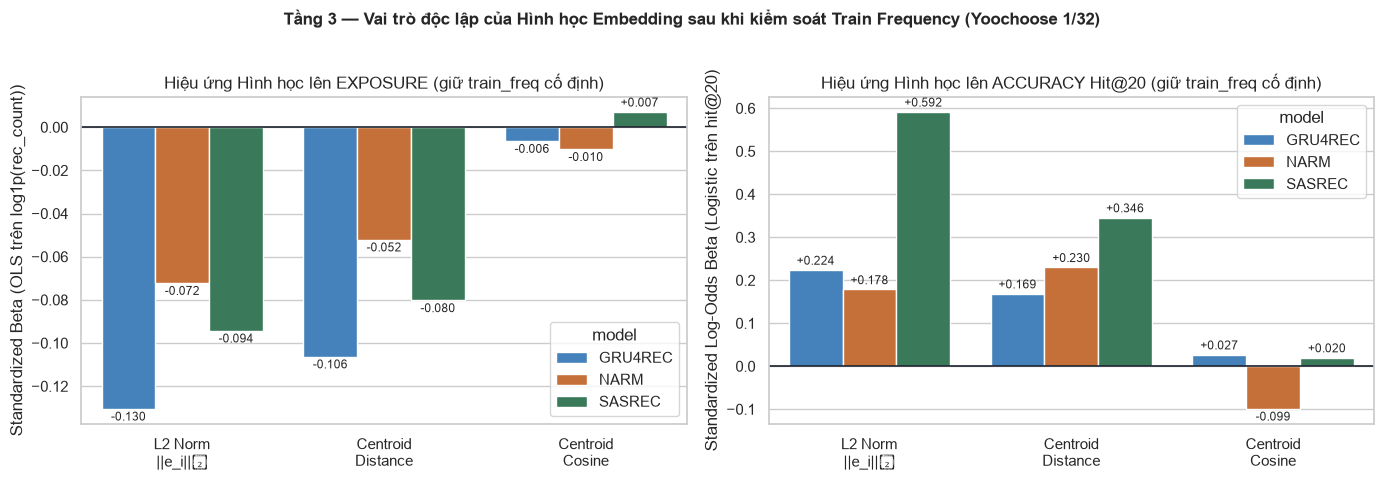

In [6]:
acc_log_frames = []
acc_log_r12_frames = []

for m in MODELS:
    for seed in SEEDS:
        enr = enriched_tables[(m, seed)]
        q_df = query_tables[(m, seed)]

        res_acc = fit_geometry_accuracy_models(q_df, enr, topk=TOPK, random_state=seed)
        res_acc["model"] = m.upper()
        acc_log_frames.append(res_acc)

        # Kiểm tra độ nhạy trên riêng query có target thuộc 12 category chuẩn
        r12_ids = set(enr.loc[enr["is_trainable_warm"] & enr["has_regular_category"], "internal_item_id"])
        q_r12 = q_df.loc[q_df["target_internal_item_id"].isin(r12_ids)].copy()
        res_acc_r12 = fit_geometry_accuracy_models(q_r12, enr.loc[enr["has_regular_category"]], topk=TOPK, random_state=seed)
        res_acc_r12["model"] = m.upper()
        acc_log_r12_frames.append(res_acc_r12)

acc_log_df = pd.concat(acc_log_frames, ignore_index=True)
acc_log_df.to_csv(STAT_TESTS_DIR / "geometry_accuracy_logistic.csv", index=False)

acc_log_seed_summary = (
    acc_log_df.groupby(["model", "geometry_variable"], sort=False)
    .agg(
        geometry_beta_std_mean=("geometry_beta_std", "mean"),
        geometry_beta_std_sd=("geometry_beta_std", "std"),
        delta_log_loss_mean=("delta_log_loss_vs_frequency", "mean"),
        mcfadden_r_squared_mean=("mcfadden_r_squared", "mean"),
    )
    .reset_index()
)
acc_log_seed_summary.to_csv(STAT_TESTS_DIR / "geometry_accuracy_logistic_seed_summary.csv", index=False)

acc_log_r12_summary = (
    pd.concat(acc_log_r12_frames, ignore_index=True)
    .groupby(["model", "geometry_variable"], sort=False)[["geometry_beta_std", "delta_log_loss_vs_frequency", "mcfadden_r_squared"]]
    .mean()
    .reset_index()
)
acc_log_r12_summary.to_csv(STAT_TESTS_DIR / "geometry_accuracy_logistic_regular12_sensitivity.csv", index=False)

# Ghép bảng nối kết cuối cùng (Exposure + Accuracy sau khi kiểm soát frequency)
final_link_df = exp_reg_seed_summary.merge(
    acc_log_seed_summary,
    on=["model", "geometry_variable"],
    suffixes=("_exposure", "_accuracy"),
)
final_link_df.to_csv(TABLES_DIR / "geometry_bias_final_link.csv", index=False)

print("=== BẢNG 4A: LOGISTIC REGRESSION CHO HIT@20 (TOÀN WARM QUERIES, KIỂM SOÁT log1p(train_freq)) ===")
display(acc_log_seed_summary)

print("\n=== BẢNG 4B: KIỂM TRA ĐỘ NHẠY LOGISTIC REGRESSION TRÊN 12 CATEGORY CHUẨN ===")
display(acc_log_r12_summary)

# Biểu đồ hiệu ứng hình học sau kiểm soát frequency (Exposure OLS vs. Accuracy Logistic)
plot_ctrl = final_link_df.loc[final_link_df["geometry_variable"] != "none"].copy()
gvar_order = ["embedding_norm", "distance_to_category_centroid", "cosine_to_category_centroid"]
gvar_labels = ["L2 Norm\n||e_i||₂", "Centroid\nDistance", "Centroid\nCosine"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.7))
sns.barplot(
    data=plot_ctrl, x="geometry_variable", y="geometry_beta_std_mean_exposure", hue="model",
    order=gvar_order, hue_order=["GRU4REC", "NARM", "SASREC"], palette=MODEL_COLORS, ax=axes[0],
)
axes[0].axhline(0.0, color="#1a202c", linewidth=1.2)
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(gvar_labels)
axes[0].set_xlabel("")
axes[0].set_ylabel("Standardized Beta (OLS trên log1p(rec_count))")
axes[0].set_title("Hiệu ứng Hình học lên EXPOSURE (giữ train_freq cố định)")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%+.3f", fontsize=8.5, padding=2)

sns.barplot(
    data=plot_ctrl, x="geometry_variable", y="geometry_beta_std_mean_accuracy", hue="model",
    order=gvar_order, hue_order=["GRU4REC", "NARM", "SASREC"], palette=MODEL_COLORS, ax=axes[1],
)
axes[1].axhline(0.0, color="#1a202c", linewidth=1.2)
axes[1].set_xticks(range(3))
axes[1].set_xticklabels(gvar_labels)
axes[1].set_xlabel("")
axes[1].set_ylabel("Standardized Log-Odds Beta (Logistic trên hit@20)")
axes[1].set_title("Hiệu ứng Hình học lên ACCURACY Hit@20 (giữ train_freq cố định)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%+.3f", fontsize=8.5, padding=2)

plt.suptitle("Tầng 3 — Vai trò độc lập của Hình học Embedding sau khi kiểm soát Train Frequency (Yoochoose 1/32)", fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "geometry_controlled_effects.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Bảng tổng hợp so sánh cấp mô hình cuối cùng & Kiểm tra Độ ổn định qua 2 Seed (`2024` vs. `2025`)

=== BẢNG 5A: SO SÁNH TỔNG HỢP CUỐI CÙNG CẤP MÔ HÌNH (YOOCHOOSE 1/32, TB 2 SEED) ===


,model,recall@20_mean,mrr@20_mean,coverage_warm@20_mean,gini_warm@20_mean,arp@20_mean,exposure_gap_popular_minus_rare_pp_mean,recall_gap_popular_minus_rare_pp_mean,spearman_freq_norm_mean,warm_cat_cosine_gap_mean,centroid_dist_gap_rare_minus_popular_mean,effective_rank_pr_mean,beta_norm_exposure_mean,beta_cosine_exposure_mean
0,GRU4REC,0.7300,0.3258,0.9121,0.8905,776.2330,88.0926,35.0084,-0.6803,0.1035,0.1841,28.4053,-0.1305,-0.0065
1,NARM,0.7349,0.3258,0.9255,0.8867,746.2542,87.6556,33.9647,-0.5504,0.1054,0.1028,29.3109,-0.0723,-0.0102
2,SASREC,0.7405,0.3281,0.9290,0.8836,709.3730,86.5791,30.2685,-0.6364,0.0741,0.1162,51.4404,-0.0943,0.0071



=== BẢNG 5B: KIỂM TRA ỔN ĐỊNH THỨ HẠNG MÔ HÌNH QUA 2 SEED (2024 vs. 2025) ===


,metric,order_seed_2024,order_seed_2025,stable_order
0,recall@20,SASREC > NARM > GRU4REC,SASREC > NARM > GRU4REC,True
1,coverage_warm@20,SASREC > NARM > GRU4REC,SASREC > NARM > GRU4REC,True
2,gini_warm@20,SASREC > NARM > GRU4REC,SASREC > NARM > GRU4REC,True
3,arp@20,SASREC > NARM > GRU4REC,SASREC > NARM > GRU4REC,True
4,spearman_freq_norm,GRU4REC > SASREC > NARM,GRU4REC > SASREC > NARM,True
5,effective_rank_pr,SASREC > NARM > GRU4REC,SASREC > GRU4REC > NARM,False


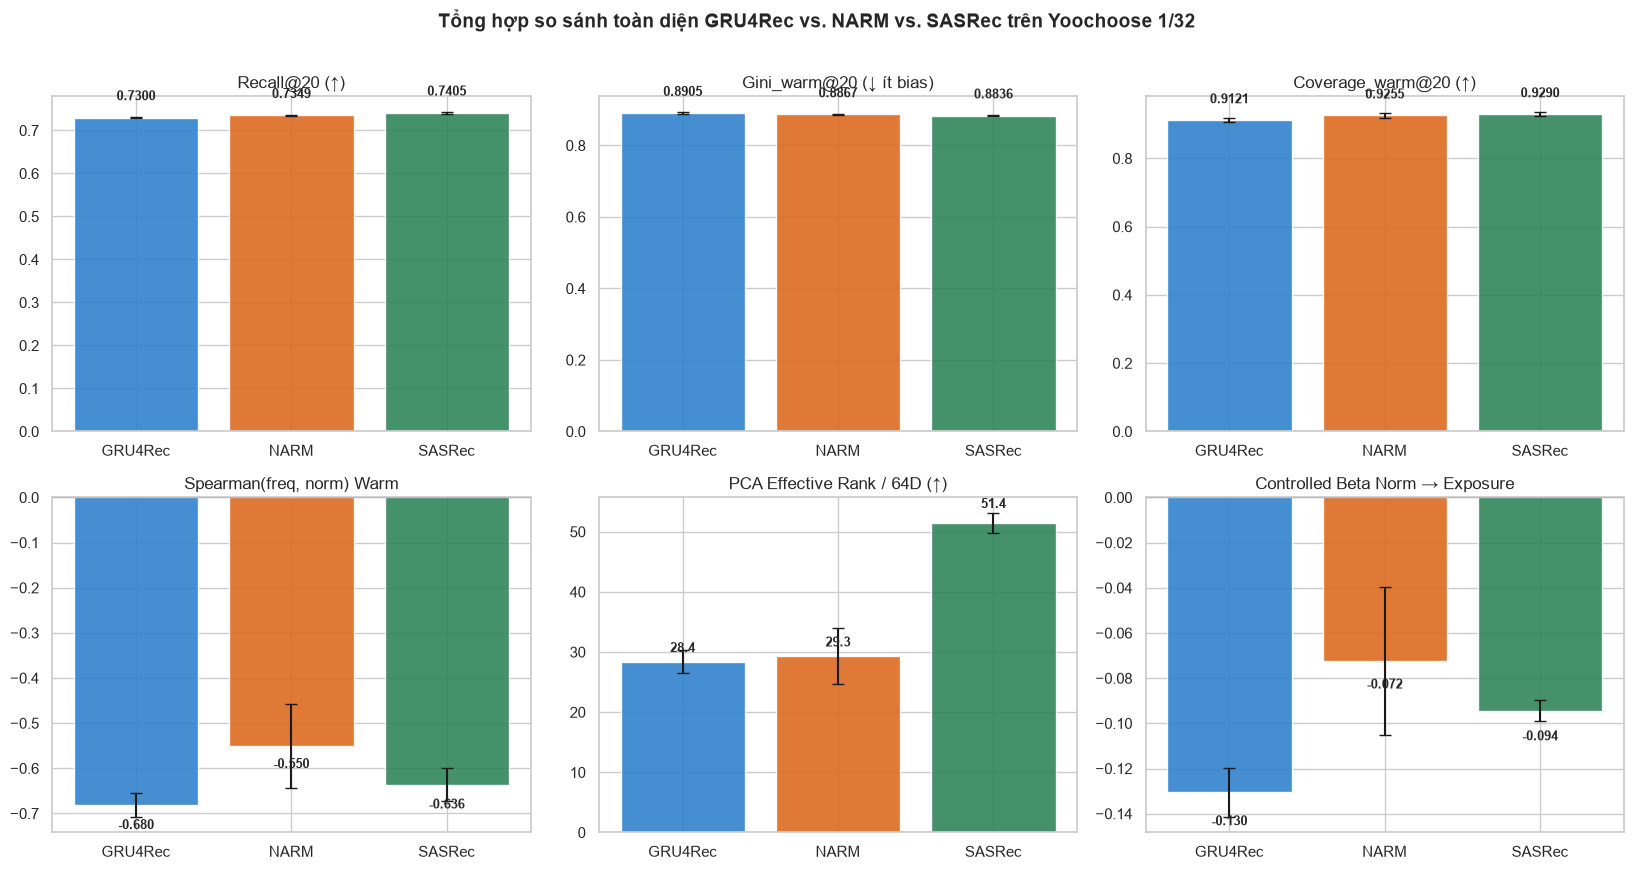

In [7]:
# Ghép đầy đủ tất cả chiều đánh giá ở cấp (model, seed) để kiểm tra độ ổn định qua 2 seed
sp_fn = core_rel_df.loc[(core_rel_df["scope"] == "warm_only") & (core_rel_df["pair"] == "train_freq <-> embedding_norm"), ["model", "seed", "rho"]].rename(columns={"rho": "spearman_freq_norm"})
sp_fr = core_rel_df.loc[(core_rel_df["scope"] == "warm_only") & (core_rel_df["pair"] == "train_freq <-> rec_count"), ["model", "seed", "rho"]].rename(columns={"rho": "spearman_freq_rec"})
sp_nr = core_rel_df.loc[(core_rel_df["scope"] == "warm_only") & (core_rel_df["pair"] == "embedding_norm <-> rec_count"), ["model", "seed", "rho"]].rename(columns={"rho": "spearman_norm_rec_raw"})
ctrl_norm_exp = exp_reg_df.loc[exp_reg_df["geometry_variable"] == "embedding_norm", ["model", "seed", "geometry_beta_std"]].rename(columns={"geometry_beta_std": "beta_norm_exposure"})
ctrl_cos_exp = exp_reg_df.loc[exp_reg_df["geometry_variable"] == "cosine_to_category_centroid", ["model", "seed", "geometry_beta_std"]].rename(columns={"geometry_beta_std": "beta_cosine_exposure"})
ctrl_norm_acc = acc_log_df.loc[acc_log_df["geometry_variable"] == "embedding_norm", ["model", "seed", "geometry_beta_std"]].rename(columns={"geometry_beta_std": "beta_norm_hit20"})
ctrl_cos_acc = acc_log_df.loc[acc_log_df["geometry_variable"] == "cosine_to_category_centroid", ["model", "seed", "geometry_beta_std"]].rename(columns={"geometry_beta_std": "beta_cosine_hit20"})

per_seed_master = (
    model_acc_df[["model", "seed", "train_time_min", "recall@20", "mrr@20", "ndcg@20", "last_item_recall@20"]]
    .merge(pop_bias_df[["model", "seed", "coverage_warm@20", "gini_warm@20", "arp@20", "popular_group_exposure_share_pct", "rare_group_exposure_share_pct"]], on=["model", "seed"])
    .merge(gap_summary_df[["model", "seed", "centroid_dist_gap_rare_minus_popular", "exposure_gap_popular_minus_rare_pp", "recall_gap_popular_minus_rare_pp"]], on=["model", "seed"])
    .merge(aniso_pca_df[["model", "seed", "effective_rank_pr"]], on=["model", "seed"])
    .merge(sp_fn, on=["model", "seed"])
    .merge(sp_fr, on=["model", "seed"])
    .merge(sp_nr, on=["model", "seed"])
    .merge(ctrl_norm_exp, on=["model", "seed"])
    .merge(ctrl_cos_exp, on=["model", "seed"])
    .merge(ctrl_norm_acc, on=["model", "seed"])
    .merge(ctrl_cos_acc, on=["model", "seed"])
)
per_seed_master.to_csv(TABLES_DIR / "seed_stability.csv", index=False)

metric_cols = [c for c in per_seed_master.columns if c not in ("model", "seed")]
final_comp = per_seed_master.groupby("model", sort=False)[metric_cols].agg(["mean", "std"])
final_comp.columns = [f"{c}_{s}" for c, s in final_comp.columns]
final_comp = final_comp.reset_index()

cos_reg_gap = cosine_gap_df.loc[cosine_gap_df["scope"] == "regular_1_12_only", ["model", "warm_same_vs_diff_mean_gap_mean"]].rename(
    columns={"warm_same_vs_diff_mean_gap_mean": "warm_cat_cosine_gap_mean"}
)
final_comp = final_comp.merge(cos_reg_gap, on="model")
final_comp.to_csv(TABLES_DIR / "final_model_comparison.csv", index=False)

# Kiểm tra độ ổn định thứ hạng qua 2 seed
rank_checks = []
for metric, higher_better in [
    ("recall@20", True),
    ("coverage_warm@20", True),
    ("gini_warm@20", False),
    ("arp@20", False),
    ("spearman_freq_norm", False),
    ("effective_rank_pr", True),
]:
    r24 = per_seed_master.loc[per_seed_master["seed"] == 2024].sort_values(metric, ascending=not higher_better)["model"].tolist()
    r25 = per_seed_master.loc[per_seed_master["seed"] == 2025].sort_values(metric, ascending=not higher_better)["model"].tolist()
    rank_checks.append({"metric": metric, "order_seed_2024": " > ".join(r24), "order_seed_2025": " > ".join(r25), "stable_order": r24 == r25})

rank_stability_df = pd.DataFrame(rank_checks)
rank_stability_df.to_csv(TABLES_DIR / "seed_rank_stability.csv", index=False)

print("=== BẢNG 5A: SO SÁNH TỔNG HỢP CUỐI CÙNG CẤP MÔ HÌNH (YOOCHOOSE 1/32, TB 2 SEED) ===")
display(
    final_comp[[
        "model", "recall@20_mean", "mrr@20_mean", "coverage_warm@20_mean", "gini_warm@20_mean",
        "arp@20_mean", "exposure_gap_popular_minus_rare_pp_mean", "recall_gap_popular_minus_rare_pp_mean",
        "spearman_freq_norm_mean", "warm_cat_cosine_gap_mean", "centroid_dist_gap_rare_minus_popular_mean",
        "effective_rank_pr_mean", "beta_norm_exposure_mean", "beta_cosine_exposure_mean",
    ]]
)

print("\n=== BẢNG 5B: KIỂM TRA ỔN ĐỊNH THỨ HẠNG MÔ HÌNH QUA 2 SEED (2024 vs. 2025) ===")
display(rank_stability_df)

# Dashboard 6 khung so sánh tổng hợp cuối cùng
fig, axes = plt.subplots(2, 3, figsize=(16.5, 8.6))
m_ord = ["GRU4REC", "NARM", "SASREC"]
fc_idx = final_comp.set_index("model").loc[m_ord]
cols_bar = [MODEL_COLORS[m] for m in m_ord]

specs = [
    (axes[0, 0], "recall@20_mean", "recall@20_std", "Recall@20 (↑)", "%.4f"),
    (axes[0, 1], "gini_warm@20_mean", "gini_warm@20_std", "Gini_warm@20 (↓ ít bias)", "%.4f"),
    (axes[0, 2], "coverage_warm@20_mean", "coverage_warm@20_std", "Coverage_warm@20 (↑)", "%.4f"),
    (axes[1, 0], "spearman_freq_norm_mean", "spearman_freq_norm_std", "Spearman(freq, norm) Warm", "%.3f"),
    (axes[1, 1], "effective_rank_pr_mean", "effective_rank_pr_std", "PCA Effective Rank / 64D (↑)", "%.1f"),
    (axes[1, 2], "beta_norm_exposure_mean", "beta_norm_exposure_std", "Controlled Beta Norm → Exposure", "%+.3f"),
]
for ax, mcol, scol, title, fmt in specs:
    vals = fc_idx[mcol].values
    errs = fc_idx[scol].values
    bars = ax.bar(["GRU4Rec", "NARM", "SASRec"], vals, yerr=errs, capsize=4, color=cols_bar, alpha=0.9)
    ax.axhline(0.0, color="#4a5568", linewidth=0.8)
    ax.set_title(title)
    for b, v in zip(bars, vals):
        offset = (abs(v) * 0.04 + 0.005) * (1 if v >= 0 else -1)
        ax.text(b.get_x() + b.get_width() / 2, v + offset, fmt % v, ha="center", va="bottom" if v >= 0 else "top", fontsize=9, fontweight="bold")

plt.suptitle("Tổng hợp so sánh toàn diện GRU4Rec vs. NARM vs. SASRec trên Yoochoose 1/32", fontsize=13.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "final_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. ĐỐI CHIẾU CHÉO TOÀN DIỆN: **Diginetica vs. Yoochoose `1/32`**

Đặt trực tiếp các hệ số hồi quy kiểm soát `log(1 + train_freq)` (`Exposure OLS` & `Hit@20 Logistic`) cùng các chỉ số cốt lõi từ hai bộ dữ liệu cạnh nhau để kết luận hiện tượng **có khái quát hóa sang Yoochoose hay không**.

=== BẢNG 6: ĐỐI CHIẾU HIỆU ỨNG HÌNH HỌC SAU KIỂM SOÁT FREQUENCY — DIGINETICA vs. YOOCHOOSE ===


,dataset,model,geometry_variable,geometry_beta_std_mean_exposure,delta_r_squared_mean,r_squared_mean,geometry_beta_std_mean_accuracy,delta_log_loss_mean,mcfadden_r_squared_mean
0,Diginetica,GRU4REC,cosine_to_category_centroid,0.1097,0.0100,0.5167,0.3202,0.0068,0.0533
1,Diginetica,GRU4REC,distance_to_category_centroid,-0.0631,0.0039,0.5105,-0.1878,0.0039,0.0491
2,Diginetica,GRU4REC,embedding_norm,0.0347,0.0007,0.5073,0.1240,0.0008,0.0447
4,Diginetica,NARM,cosine_to_category_centroid,0.1095,0.0118,0.5208,0.3161,0.0102,0.0589
5,Diginetica,NARM,distance_to_category_centroid,-0.0559,0.0030,0.5120,-0.2246,0.0056,0.0523
6,Diginetica,NARM,embedding_norm,0.0701,0.0033,0.5123,0.1602,0.0022,0.0472
8,Diginetica,SASREC,cosine_to_category_centroid,0.0833,0.0066,0.5010,0.3884,0.0135,0.0543
9,Diginetica,SASREC,distance_to_category_centroid,-0.0190,0.0003,0.4947,-0.2588,0.0075,0.0456
10,Diginetica,SASREC,embedding_norm,0.1002,0.0057,0.5000,0.2492,0.0031,0.0392
13,Yoochoose 1/32,GRU4REC,embedding_norm,-0.1305,0.0100,0.6632,0.2238,0.0028,0.0532



=== R² CỦA MÔ HÌNH CHỈ CÓ log(1 + train_freq) CHO EXPOSURE ===


,dataset,model,r_squared_mean,mcfadden_r_squared_mean
3,Diginetica,GRU4REC,0.5067,0.0434
7,Diginetica,NARM,0.5091,0.0440
11,Diginetica,SASREC,0.4944,0.0346
12,Yoochoose 1/32,GRU4REC,0.6532,0.0485
16,Yoochoose 1/32,NARM,0.6477,0.0440
20,Yoochoose 1/32,SASREC,0.6109,0.0388


D:\Temp\ipykernel_8464\3391624453.py:50: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
D:\Temp\ipykernel_8464\3391624453.py:51: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.savefig(FIGURES_DIR / "diginetica_vs_yoochoose_controlled_effects.png", dpi=160, bbox_inches="tight")
d:\DL\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


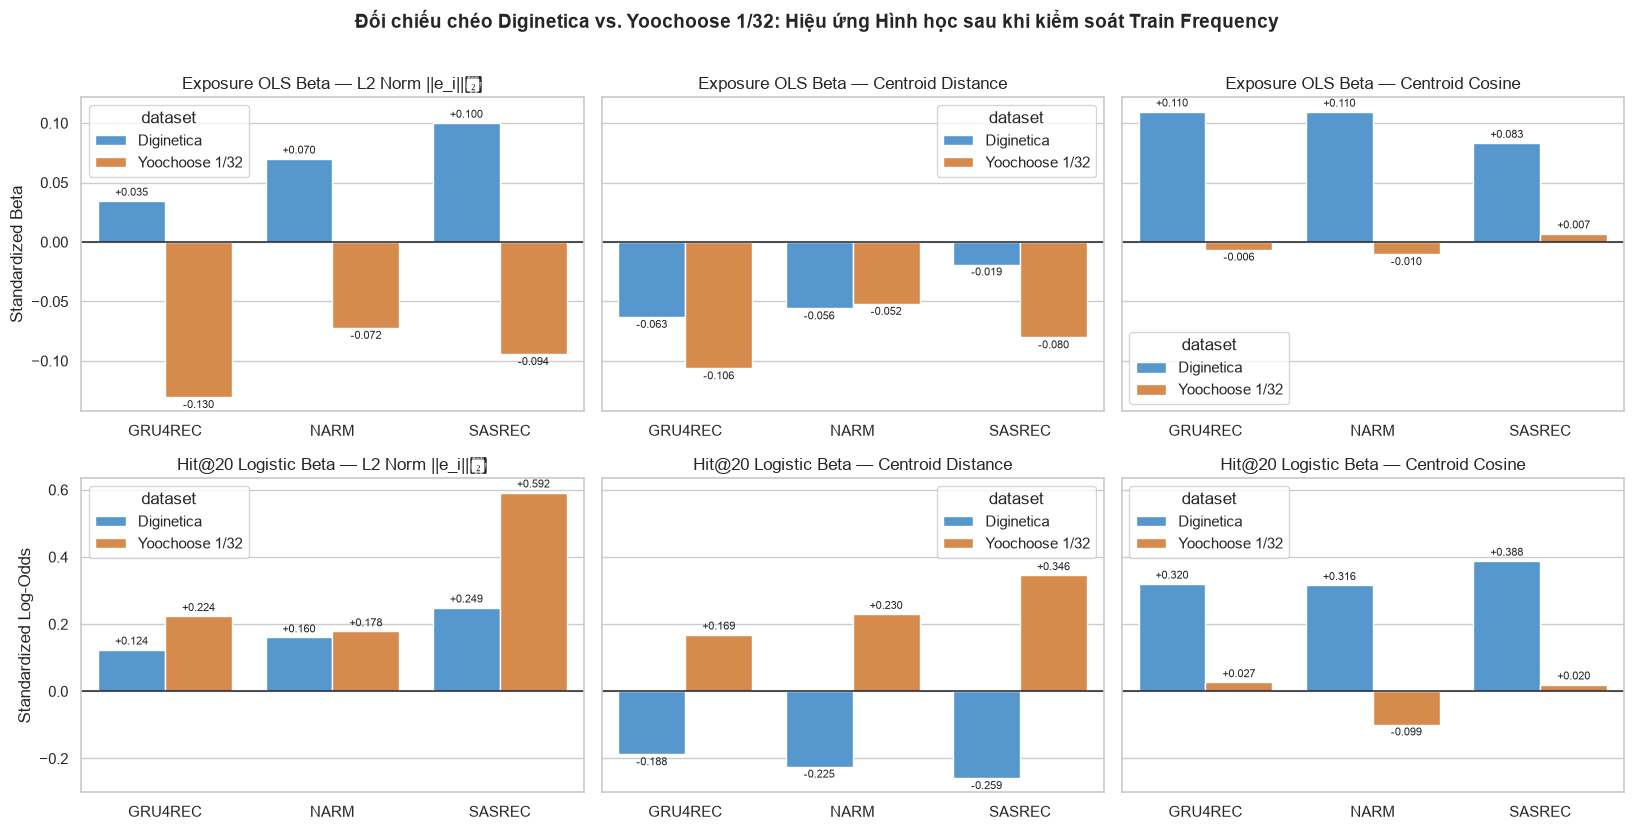

In [8]:
digi_link = pd.read_csv(DIGI_PATHS["tables_dir"] / "geometry_bias_final_link.csv")
digi_link.insert(0, "dataset", "Diginetica")

yoo_link = final_link_df.copy()
yoo_link.insert(0, "dataset", "Yoochoose 1/32")

common_cols = [
    "dataset", "model", "geometry_variable",
    "geometry_beta_std_mean_exposure", "delta_r_squared_mean", "r_squared_mean",
    "geometry_beta_std_mean_accuracy", "delta_log_loss_mean", "mcfadden_r_squared_mean",
]
cross_link_df = pd.concat([digi_link[common_cols], yoo_link[common_cols]], ignore_index=True)
cross_link_df.to_csv(TABLES_DIR / "diginetica_vs_yoochoose_final_synthesis.csv", index=False)

print("=== BẢNG 6: ĐỐI CHIẾU HIỆU ỨNG HÌNH HỌC SAU KIỂM SOÁT FREQUENCY — DIGINETICA vs. YOOCHOOSE ===")
display(cross_link_df.loc[cross_link_df["geometry_variable"] != "none"])

# Kiểm tra R² của mô hình chỉ có frequency trên 2 bộ dữ liệu
print("\n=== R² CỦA MÔ HÌNH CHỈ CÓ log(1 + train_freq) CHO EXPOSURE ===")
display(cross_link_df.loc[cross_link_df["geometry_variable"] == "none", ["dataset", "model", "r_squared_mean", "mcfadden_r_squared_mean"]])

# Biểu đồ đối chiếu chéo Diginetica vs. Yoochoose về hiệu ứng kiểm soát frequency
fig, axes = plt.subplots(2, 3, figsize=(16.5, 8.2), sharey="row")
ds_pal = {"Diginetica": "#4299e1", "Yoochoose 1/32": "#ed8936"}
m_ord = ["GRU4REC", "NARM", "SASREC"]

for col_i, (gvar, glbl) in enumerate([
    ("embedding_norm", "L2 Norm ||e_i||₂"),
    ("distance_to_category_centroid", "Centroid Distance"),
    ("cosine_to_category_centroid", "Centroid Cosine"),
]):
    sub = cross_link_df.loc[cross_link_df["geometry_variable"] == gvar]
    sns.barplot(data=sub, x="model", y="geometry_beta_std_mean_exposure", hue="dataset", order=m_ord, palette=ds_pal, ax=axes[0, col_i])
    axes[0, col_i].axhline(0.0, color="#1a202c", linewidth=1.1)
    axes[0, col_i].set_title(f"Exposure OLS Beta — {glbl}")
    axes[0, col_i].set_xlabel("")
    axes[0, col_i].set_ylabel("Standardized Beta" if col_i == 0 else "")
    for container in axes[0, col_i].containers:
        axes[0, col_i].bar_label(container, fmt="%+.3f", fontsize=8, padding=2)

    sns.barplot(data=sub, x="model", y="geometry_beta_std_mean_accuracy", hue="dataset", order=m_ord, palette=ds_pal, ax=axes[1, col_i])
    axes[1, col_i].axhline(0.0, color="#1a202c", linewidth=1.1)
    axes[1, col_i].set_title(f"Hit@20 Logistic Beta — {glbl}")
    axes[1, col_i].set_xlabel("")
    axes[1, col_i].set_ylabel("Standardized Log-Odds" if col_i == 0 else "")
    for container in axes[1, col_i].containers:
        axes[1, col_i].bar_label(container, fmt="%+.3f", fontsize=8, padding=2)

plt.suptitle("Đối chiếu chéo Diginetica vs. Yoochoose 1/32: Hiệu ứng Hình học sau khi kiểm soát Train Frequency", fontsize=13.5, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "diginetica_vs_yoochoose_controlled_effects.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Kiểm tra đầy đủ toàn bộ đầu ra File 08

In [9]:
expected_08 = [
    TABLES_DIR / "geometry_bias_group_summary.csv",
    TABLES_DIR / "geometry_bias_group_seed_summary.csv",
    TABLES_DIR / "geometry_bias_gap_summary.csv",
    TABLES_DIR / "geometry_bias_gap_seed_summary.csv",
    TABLES_DIR / "bias_geometry_relationship.csv",
    TABLES_DIR / "within_bin_norm_rec.csv",
    TABLES_DIR / "geometry_bias_final_link.csv",
    TABLES_DIR / "seed_stability.csv",
    TABLES_DIR / "seed_rank_stability.csv",
    TABLES_DIR / "final_model_comparison.csv",
    TABLES_DIR / "diginetica_vs_yoochoose_final_synthesis.csv",
    STAT_TESTS_DIR / "geometry_output_correlations.csv",
    STAT_TESTS_DIR / "norm_rec_ols_summary.csv",
    STAT_TESTS_DIR / "geometry_exposure_regression.csv",
    STAT_TESTS_DIR / "geometry_exposure_regression_seed_summary.csv",
    STAT_TESTS_DIR / "geometry_accuracy_logistic.csv",
    STAT_TESTS_DIR / "geometry_accuracy_logistic_seed_summary.csv",
    FIGURES_DIR / "geometry_bias_group_link.png",
    FIGURES_DIR / "frequency_recommendation_relationship.png",
    FIGURES_DIR / "norm_recommendation_relationship.png",
    FIGURES_DIR / "geometry_controlled_effects.png",
    FIGURES_DIR / "final_model_comparison.png",
    FIGURES_DIR / "diginetica_vs_yoochoose_controlled_effects.png",
]
missing_08 = [str(p) for p in expected_08 if not p.is_file()]
assert not missing_08, f"Thiếu đầu ra File 08: {missing_08}"
print(f"ĐÃ KIỂM CHỨNG ĐỦ {len(expected_08)}/{len(expected_08)} FILE ĐẦU RA FILE 08 YOOCHOOSE.")

ĐÃ KIỂM CHỨNG ĐỦ 23/23 FILE ĐẦU RA FILE 08 YOOCHOOSE.


## 10. Kết luận khoa học chính thức (Yoochoose + Đối chiếu Diginetica) & Giới hạn diễn giải

In [10]:
yoo_norm_exp = final_link_df.loc[final_link_df["geometry_variable"] == "embedding_norm", "geometry_beta_std_mean_exposure"]
yoo_norm_acc = final_link_df.loc[final_link_df["geometry_variable"] == "embedding_norm", "geometry_beta_std_mean_accuracy"]
yoo_cos_exp = final_link_df.loc[final_link_df["geometry_variable"] == "cosine_to_category_centroid", "geometry_beta_std_mean_exposure"]
yoo_cos_acc = final_link_df.loc[final_link_df["geometry_variable"] == "cosine_to_category_centroid", "geometry_beta_std_mean_accuracy"]
yoo_r2_freq = final_link_df.loc[final_link_df["geometry_variable"] == "none", "r_squared_mean"]
yoo_dr2_max = final_link_df.loc[final_link_df["geometry_variable"] != "none", "delta_r_squared_mean"].max()

conclusions = [
    (
        "H1: Popularity Bias ở đầu ra & lợi thế của SASRec",
        "LẶP LẠI HOÀN TOÀN",
        "Trên cả Diginetica và Yoochoose, SASRec đạt đồng thời Recall/MRR/NDCG@20 cao nhất, Coverage@20 cao nhất, Gini@20 thấp nhất, ARP@20 thấp nhất và Rare Recall@20 cao nhất. Tuy nhiên bias trên Yoochoose khốc liệt hơn nhiều (Gini ~0.884–0.891, Popular nhận 88–89% exposure, Rare chỉ 1.1–1.4%) và GRU4Rec là mô hình bias mạnh nhất trên Yoochoose.",
    ),
    (
        "H2: Tương quan âm mạnh Spearman(train_freq, L2 norm)",
        "LẶP LẠI HOÀN TOÀN",
        "Cả 3 mô hình × 2 seed trên Yoochoose đều có Spearman(freq, norm) âm mạnh (GRU4Rec -0.680, SASRec -0.636, NARM -0.550), giữ nguyên đúng thứ hạng độ lớn GRU4Rec > SASRec > NARM như Diginetica (-0.745 > -0.707 > -0.668).",
    ),
    (
        "H3: Cấu trúc Category Warm vs. Cold Item (Option B)",
        "LẶP LẠI (CÓ ĐẶC THÙ ĐỘ MỊN CATEGORY)",
        "Warm item tự học cấu trúc 12 category chuẩn (cosine gap +0.074 đến +0.105, p < 0.0001; nhỏ hơn Diginetica 0.41–0.44 vì Yoochoose chỉ có 12 category thô). Cold item có cosine gần 0 ở cả hai bộ dữ liệu, khẳng định giới hạn của baseline ID-only.",
    ),
    (
        "H4: Nghịch lý biến gây nhiễu frequency (Norm → Exposure / Hit@20)",
        "KIỂM CHỨNG TRỰC TIẾP",
        f"Tương quan thô norm ↔ rec_count âm mạnh (do frequency gây nhiễu), nhưng sau khi giữ log(1+train_freq) cố định, beta của norm chuyển thành [{yoo_norm_exp.min():+.3f}, {yoo_norm_exp.max():+.3f}] cho Exposure và [{yoo_norm_acc.min():+.3f}, {yoo_norm_acc.max():+.3f}] cho Hit@20; beta cosine tâm category là [{yoo_cos_exp.min():+.3f}, {yoo_cos_exp.max():+.3f}] (Exposure) và [{yoo_cos_acc.min():+.3f}, {yoo_cos_acc.max():+.3f}] (Hit@20).",
    ),
    (
        "H5: Mức đóng góp giải thích của Geometry so với Frequency",
        "NHẤT QUÁN VỚI DIGINETICA",
        f"Riêng log(1+train_freq) đã giải thích R² ≈ {yoo_r2_freq.min()*100:.1f}%–{yoo_r2_freq.max()*100:.1f}% biến thiên log(1+rec_count); phần ΔR² bổ sung từ geometry chỉ đạt tối đa {yoo_dr2_max:.4f}. Geometry là tín hiệu đi kèm có ý nghĩa thống kê, không phải nguyên nhân duy nhất và chưa đủ để chứng minh quan hệ nhân quả.",
    ),
    (
        "H6: Giải thích cấp mô hình (vì sao SASRec ít bias hơn?)",
        "MỞ RỘNG BẰNG EFFECTIVE RANK PCA",
        "Độ tách biệt centroid gap giữa Popular và Rare không giải thích một-một thứ hạng bias giữa 3 mô hình trên cả 2 dataset. Tuy nhiên trên Yoochoose, SASRec nổi bật với PCA Effective Rank ≈ 51.4/64 (gấp ~1.8× GRU4Rec/NARM), gợi ý không gian biểu diễn ít suy biến chiều hơn.",
    ),
]

conclusions_df = pd.DataFrame(conclusions, columns=["gia_thuyet_kiem_chung", "trang_thai_so_voi_diginetica", "tom_tat_bang_chung"])
conclusions_df.to_csv(TABLES_DIR / "final_conclusions.csv", index=False)
display(conclusions_df)
print("\nHOÀN TẤT TOÀN BỘ PIPELINE PHÂN TÍCH YOOCHOOSE (00 → 08)!")

,gia_thuyet_kiem_chung,trang_thai_so_voi_diginetica,tom_tat_bang_chung
0,H1: Popularity Bias ở đầu ra & lợi thế của SASRec,LẶP LẠI HOÀN TOÀN,"Trên cả Diginetica và Yoochoose, SASRec đạt đồ..."
1,"H2: Tương quan âm mạnh Spearman(train_freq, L2...",LẶP LẠI HOÀN TOÀN,Cả 3 mô hình × 2 seed trên Yoochoose đều có Sp...
2,H3: Cấu trúc Category Warm vs. Cold Item (Opti...,LẶP LẠI (CÓ ĐẶC THÙ ĐỘ MỊN CATEGORY),Warm item tự học cấu trúc 12 category chuẩn (c...
3,H4: Nghịch lý biến gây nhiễu frequency (Norm →...,KIỂM CHỨNG TRỰC TIẾP,Tương quan thô norm ↔ rec_count âm mạnh (do fr...
4,H5: Mức đóng góp giải thích của Geometry so vớ...,NHẤT QUÁN VỚI DIGINETICA,Riêng log(1+train_freq) đã giải thích R² ≈ 61....
5,H6: Giải thích cấp mô hình (vì sao SASRec ít b...,MỞ RỘNG BẰNG EFFECTIVE RANK PCA,Độ tách biệt centroid gap giữa Popular và Rare...



HOÀN TẤT TOÀN BỘ PIPELINE PHÂN TÍCH YOOCHOOSE (00 → 08)!
